# FLAML hyperparameter tuning: Ridge, Random Forest and CatBoost

This executed notebook preserves the data, row order, chronological holdout rule and model-specific feature processing in `Models_main.ipynb`. FLAML's **Cost-Frugal Optimization (CFO)** searches each model independently, minimizing validation RMSE in monthly rent units. No rows are subsampled and no random train/validation split is introduced.

The original model configuration is evaluated first in each search, so improvements are measured against a freshly evaluated baseline on identical data. Validation is used for both tuning and CatBoost early stopping: these are **model-selection scores, not unbiased test scores**. The provided test file has no rent labels; only predictions can be reported for it.

Dependency: install `flaml==2.8.0` in addition to the repository requirements (`%pip install flaml==2.8.0` if needed). Only FLAML's generic tuning API is needed; its optional AutoML extra is not required. [FLAML tuning documentation](https://microsoft.github.io/FLAML/docs/Use-Cases/Tune-User-Defined-Function/).

In [1]:
from pathlib import Path
import hashlib, json, platform, time, warnings
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from catboost import CatBoostRegressor
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='flaml.automl is not available.*')
    from flaml import tune, CFO

ROOT = Path.cwd()
assert (ROOT / 'Models_main.ipynb').exists(), 'Run from the repository root.'
OUT = ROOT / 'derived' / 'flaml_tuning'
PLOTS = ROOT / 'plots' / 'flaml_tuning'
PREDS = ROOT / 'predictions' / 'flaml_tuning'
for path in (OUT, PLOTS, PREDS):
    path.mkdir(parents=True, exist_ok=True)
SEED, N_JOBS = 42, 4
# Fixed trial counts avoid wall-clock-dependent truncation.
MAX_TRIALS = {'Ridge': 24, 'Random Forest': 12, 'CatBoost': 12}
versions = {p: version(p) for p in ['flaml', 'numpy', 'pandas', 'scikit-learn', 'catboost', 'matplotlib']}
display(pd.Series(versions, name='version').to_frame())

,version
flaml,2.8.0
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
catboost,1.2.10
matplotlib,3.11.2


## 1. Exact source data and chronological split
The executable cutoff expression is copied from the main notebook, including its strict `>` comparison. Input hashes and original row indices are saved to make this run auditable.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("derived/train_cleaned_enriched.csv")
test = pd.read_csv("derived/test_cleaned_enriched.csv")
approval_dates = pd.to_datetime(train["RENT_APPROVAL_DATE"])
cutoff = (approval_dates.max().to_period("M").start_time - pd.DateOffset(months=12))

is_validation = approval_dates > cutoff
training_data = train.loc[~is_validation]
validation_data = train.loc[is_validation]

print(f"Training Data shape: {training_data.shape}, Validation Data shape: {validation_data.shape}")

Training Data shape: (114683, 21), Validation Data shape: (35158, 21)


In [3]:
assert set(training_data.index).isdisjoint(validation_data.index)
assert len(training_data) + len(validation_data) == len(train)
assert 'MONTHLY_RENT' not in test.columns
split_table = pd.DataFrame([
    {'partition': name, 'rows': len(frame), 'date_min': frame.RENT_APPROVAL_DATE.min(),
     'date_max': frame.RENT_APPROVAL_DATE.max(), 'target_available': 'MONTHLY_RENT' in frame}
    for name, frame in [('train', training_data), ('validation', validation_data), ('test', test)]
])
display(split_table)
print('Exact cutoff:', cutoff)
manifest = {'source_notebook_sha256': hashlib.sha256((ROOT/'Models_main.ipynb').read_bytes()).hexdigest(),
            'input_sha256': {f: hashlib.sha256((ROOT/f).read_bytes()).hexdigest() for f in
                            ['derived/train_cleaned_enriched.csv', 'derived/test_cleaned_enriched.csv']},
            'cutoff': str(cutoff), 'validation_rule': 'approval_dates > cutoff',
            'seed': SEED, 'versions': versions, 'python': platform.python_version(),
            'max_trials': MAX_TRIALS}
(OUT/'run_manifest.json').write_text(json.dumps(manifest, indent=2))
pd.DataFrame({'source_row': train.index, 'partition': np.where(is_validation, 'validation', 'train')}).to_csv(OUT/'split_membership.csv', index=False)
split_table.to_csv(OUT/'data_partitions.csv', index=False)

,partition,rows,date_min,date_max,target_available
0,train,114683,2021-01-01,2024-03-01,True
1,validation,35158,2024-04-01,2025-03-01,True
2,test,50000,2025-03-01,2026-07-01,False


Exact cutoff: 2024-03-01 00:00:00


## 2. Preserve preprocessing
Ridge uses the main notebook's scaled numeric features, one-hot categories and cross-fitted location target encoding. Random Forest uses the same features and encodings without scaling. CatBoost receives the original 17 features and five native categorical columns. All learned preprocessing is fitted only on training rows during tuning. Encoded matrices can be cached across trials because preprocessing settings are fixed; target encoding uses `fit_transform` to retain training cross-fitting.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

TARGET = "MONTHLY_RENT"
NUMERIC_FEATURES = ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 
                    'HDB_LATITUDE', 'HDB_LONGITUDE', 'HDB_YEAR_COMPLETED', 
                    'NEAREST_MRT_KM', 'NEAREST_SCHOOL_KM','NEAREST_MALL_KM', 
                    'APPROVAL_YEAR', 'APPROVAL_MONTH', 'MONTH_INDEX', 'BUILDING_AGE']
ONEHOT_FEATURES = ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "HDB_PLANNING_AREA"]
BLOCK_FEATURES = ["LOCATION_KEY"]


def split_xy(data):
    """Separate the optional target and remove constant columns without mutating data."""
    X = data.drop(columns=[TARGET], errors="ignore").copy()
    y = data[TARGET].copy() if TARGET in data.columns else None
    return X, y


def make_preprocessor():
    """Return a fresh preprocessor; fit only on the training partition."""
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        # Keep all categories for Ridge; unseen categories become all-zero indicators.
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    block_pipeline = Pipeline([
        ("encode", TargetEncoder(target_type="continuous", smooth="auto",
                                 cv=5, shuffle=True, random_state=42)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, ONEHOT_FEATURES),
        ("block", block_pipeline, BLOCK_FEATURES),
    ], remainder="drop", sparse_threshold=0)


def preprocess(data, *, preprocessor=None):
    """Return (encoded X, optional y, fitted preprocessor).

    Omit preprocessor to fit on labeled training data (at least 5 rows).
    Pass the returned preprocessor to transform validation or test data.
    """
    X, y = split_xy(data)
    if preprocessor is None:
        if y is None:
            raise ValueError("Training data must contain MONTHLY_RENT.")
        if y.isna().any():
            raise ValueError("Training targets must not contain missing values.")
        if len(X) < 5:
            raise ValueError("TargetEncoder with cv=5 requires at least 5 training rows.")
        preprocessor = make_preprocessor()
        encoded = preprocessor.fit_transform(X, y)
    else:
        encoded = preprocessor.transform(X)
    encoded = pd.DataFrame(encoded, columns=preprocessor.get_feature_names_out(), index=X.index)
    return encoded, y, preprocessor

In [5]:
X_fit_raw, y_fit_raw = split_xy(training_data)
X_val_raw, y_val_raw = split_xy(validation_data)
ridge_preprocessor = make_preprocessor()
X_ridge_train = ridge_preprocessor.fit_transform(X_fit_raw, y_fit_raw)
X_ridge_val = ridge_preprocessor.transform(X_val_raw)
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# Trees do not require feature scaling, so this preprocessor imputes numeric
# values, one-hot encodes low-cardinality categories, and target-encodes
# LOCATION_KEY. It is fitted on training data only.
rf_numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
])
rf_categorical_pipeline = Pipeline([
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
rf_location_pipeline = Pipeline([
    ("encode", TargetEncoder(target_type="continuous", smooth="auto",
                                 cv=5, shuffle=True, random_state=42)),
])
rf_preprocessor = ColumnTransformer([
    ("numeric", rf_numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", rf_categorical_pipeline, ONEHOT_FEATURES),
    ("location", rf_location_pipeline, BLOCK_FEATURES),
], remainder="drop", sparse_threshold=0)

X_rf_train = rf_preprocessor.fit_transform(X_fit_raw, y_fit_raw)
X_rf_val = rf_preprocessor.transform(X_val_raw)
rf_feature_names = rf_preprocessor.get_feature_names_out()

/Users/apple/miniconda3/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/apple/miniconda3/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [6]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error

CATBOOST_ALL_FEATURES = ["FLOOR_AREA_SQM","LEASE_COMMENCE_DATE","HDB_LATITUDE",
    "HDB_LONGITUDE","HDB_YEAR_COMPLETED","NEAREST_MRT_KM","NEAREST_SCHOOL_KM",
    "NEAREST_MALL_KM","APPROVAL_YEAR","APPROVAL_MONTH","MONTH_INDEX","BUILDING_AGE",
    "TOWN","FLAT_TYPE","FLAT_MODEL","HDB_PLANNING_AREA","LOCATION_KEY",
]
CATBOOST_CATEGORICAL = ["TOWN","FLAT_TYPE","FLAT_MODEL","HDB_PLANNING_AREA","LOCATION_KEY"]

def make_catboost_features(data):
    """Build target-independent features while preserving input row order."""

    # Data has already been cleaned; ensure CatBoost categorical columns are strings.
    X = data[CATBOOST_ALL_FEATURES].copy()
    return X


X_cb_train = make_catboost_features(training_data)
y_cb_train = pd.to_numeric(training_data[TARGET], errors="raise")

X_cb_val = make_catboost_features(validation_data)
y_cb_val = pd.to_numeric(validation_data[TARGET], errors="raise")

X_cb_test = make_catboost_features(test)

print(f"Train: {X_cb_train.shape}")
print(f"Validation: {X_cb_val.shape}")

Train: (114683, 17)
Validation: (35158, 17)


## 3. Search spaces and evaluation
Each search starts at the original notebook configuration, followed by adaptive CFO suggestions (seed 42). All trials use the complete fixed training and validation partitions. The trial counts are configurable above. CatBoost retains the original 100-round early stopping; its selected tree count is recorded and used for the final refit. Four threads bound resource use. Training metrics use the cached cross-fitted design matrices for Ridge and Random Forest.

These are bounded searches, not exhaustive optimizations. Each model completes the fixed number of trials above; runtime depends on machine speed.

In [7]:
BASELINES = {
    'Ridge': {'alpha': 1.0},
    'Random Forest': {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.7},
    'CatBoost': {'iterations': 2000, 'depth': 6, 'learning_rate': 0.05, 'l2_leaf_reg': 5.0},
}
SPACES = {
    'Ridge': {'alpha': tune.loguniform(1e-4, 1e5)},
    'Random Forest': {'n_estimators': tune.randint(80, 401), 'max_depth': tune.randint(8, 31),
                      'min_samples_leaf': tune.randint(1, 21), 'max_features': tune.uniform(0.3, 1.0)},
    'CatBoost': {'iterations': tune.randint(500, 2501), 'depth': tune.randint(4, 9),
                 'learning_rate': tune.loguniform(0.015, 0.15), 'l2_leaf_reg': tune.loguniform(1.0, 30.0)},
}
space_table = pd.DataFrame([
    ['Ridge', 'alpha', 'log-uniform [0.0001, 100000]'],
    ['Random Forest', 'n_estimators', 'integer 80–400'],
    ['Random Forest', 'max_depth', 'integer 8–30'],
    ['Random Forest', 'min_samples_leaf', 'integer 1–20'],
    ['Random Forest', 'max_features', 'uniform [0.3, 1.0]'],
    ['CatBoost', 'iterations', 'integer 500–2500; early stopping patience 100'],
    ['CatBoost', 'depth', 'integer 4–8'],
    ['CatBoost', 'learning_rate', 'log-uniform [0.015, 0.15]'],
    ['CatBoost', 'l2_leaf_reg', 'log-uniform [1, 30]'],
], columns=['model', 'hyperparameter', 'search_range'])
display(space_table)
space_table.to_csv(OUT/'search_spaces.csv', index=False)

def make_model(name, config):
    if name == 'Ridge':
        return Ridge(**config)
    if name == 'Random Forest':
        return RandomForestRegressor(**config, random_state=SEED, n_jobs=N_JOBS)
    return CatBoostRegressor(**config, loss_function='RMSE', eval_metric='RMSE',
                            random_seed=SEED, thread_count=N_JOBS, allow_writing_files=False)

MATRICES = {'Ridge': (X_ridge_train, X_ridge_val),
            'Random Forest': (X_rf_train, X_rf_val), 'CatBoost': (X_cb_train, X_cb_val)}
history, best_models, best_configs, best_predictions, analyses = [], {}, {}, {}, {}

def scores(y, pred):
    return {'rmse': root_mean_squared_error(y, pred), 'mae': mean_absolute_error(y, pred), 'r2': r2_score(y, pred)}

def run_search(name):
    Xtr, Xva = MATRICES[name]
    started = time.perf_counter()
    best_loss = np.inf
    trial_number = 0
    def objective(config):
        nonlocal best_loss, trial_number
        trial_number += 1
        t0 = time.perf_counter()
        model = make_model(name, config)
        if name == 'CatBoost':
            model.fit(Xtr, y_fit_raw, cat_features=CATBOOST_CATEGORICAL,
                      eval_set=(Xva, y_val_raw), early_stopping_rounds=100, use_best_model=True, verbose=False)
        else:
            model.fit(Xtr, y_fit_raw)
        pred = model.predict(Xva)
        validation = scores(y_val_raw, pred)
        training = scores(y_fit_raw, model.predict(Xtr))
        row = {'model': name, 'trial': trial_number, 'is_baseline': trial_number == 1,
               **{'val_'+k: v for k, v in validation.items()},
               **{'train_'+k: v for k, v in training.items()},
               'trial_seconds': time.perf_counter()-t0, 'elapsed_seconds': time.perf_counter()-started,
               'selected_trees': model.tree_count_ if name == 'CatBoost' else config.get('n_estimators', np.nan),
               'config': json.dumps(config, default=lambda x: x.item())}
        history.append(row)
        pd.DataFrame(history).to_csv(OUT/'trial_history.csv', index=False)
        if validation['rmse'] < best_loss:
            best_loss = validation['rmse']
            best_models[name], best_configs[name], best_predictions[name] = model, dict(config), pred
        print(f"{name} trial {trial_number}: validation RMSE={validation['rmse']:.3f}; {row['trial_seconds']:.1f}s", flush=True)
        return {'rmse': validation['rmse']}
    searcher = CFO(space=SPACES[name], metric='rmse', mode='min', seed=SEED,
                   points_to_evaluate=[BASELINES[name]])
    analyses[name] = tune.run(objective, config=SPACES[name], search_alg=searcher,
                              metric='rmse', mode='min', num_samples=MAX_TRIALS[name],
                              use_ray=False, verbose=0)
    assert trial_number >= 2, f'{name}: increase time budget to evaluate more than baseline'
    assert np.isclose(analyses[name].best_result['rmse'], best_loss)


,model,hyperparameter,search_range
0,Ridge,alpha,"log-uniform [0.0001, 100000]"
1,Random Forest,n_estimators,integer 80–400
2,Random Forest,max_depth,integer 8–30
3,Random Forest,min_samples_leaf,integer 1–20
4,Random Forest,max_features,"uniform [0.3, 1.0]"
5,CatBoost,iterations,integer 500–2500; early stopping patience 100
6,CatBoost,depth,integer 4–8
7,CatBoost,learning_rate,"log-uniform [0.015, 0.15]"
8,CatBoost,l2_leaf_reg,"log-uniform [1, 30]"


### Ridge

In [8]:
run_search('Ridge')
display(pd.DataFrame(history).loc[lambda d: d.model.eq('Ridge')].sort_values('val_rmse').head(5))

Ridge trial 1: validation RMSE=620.093; 0.0s


Ridge trial 2: validation RMSE=620.200; 0.0s


Ridge trial 3: validation RMSE=620.081; 0.0s


Ridge trial 4: validation RMSE=620.080; 0.0s


Ridge trial 5: validation RMSE=620.080; 0.0s


Ridge trial 6: validation RMSE=620.080; 0.0s


... (15 outputs left out)

Ridge trial 22: validation RMSE=620.080; 0.0s


Ridge trial 23: validation RMSE=620.080; 0.0s


Ridge trial 24: validation RMSE=620.080; 0.0s


,model,trial,is_baseline,val_rmse,val_mae,val_r2,train_rmse,train_mae,train_r2,trial_seconds,elapsed_seconds,selected_trees,config
18,Ridge,19,False,620.079949,466.414579,0.115206,498.242507,382.496361,0.53573,0.025535,0.543417,NaN,"{""alpha"": 0.0001}"
23,Ridge,24,False,620.079949,466.414580,0.115206,498.242507,382.496361,0.53573,0.025668,0.676479,NaN,"{""alpha"": 0.00014267527773458691}"
22,Ridge,23,False,620.079949,466.414580,0.115206,498.242507,382.496361,0.53573,0.025075,0.649863,NaN,"{""alpha"": 0.00014424442133156043}"
21,Ridge,22,False,620.079949,466.414580,0.115206,498.242507,382.496361,0.53573,0.025653,0.623609,NaN,"{""alpha"": 0.00014598786835405146}"
20,Ridge,21,False,620.079949,466.414580,0.115206,498.242507,382.496361,0.53573,0.026237,0.596915,NaN,"{""alpha"": 0.00014793945445493926}"


### Random Forest

In [9]:
run_search('Random Forest')
display(pd.DataFrame(history).loc[lambda d: d.model.eq('Random Forest')].sort_values('val_rmse').head(5))

Random Forest trial 1: validation RMSE=483.112; 24.0s


Random Forest trial 2: validation RMSE=480.662; 24.4s


Random Forest trial 3: validation RMSE=483.112; 25.8s


Random Forest trial 4: validation RMSE=478.661; 31.1s


Random Forest trial 5: validation RMSE=478.408; 39.7s


Random Forest trial 6: validation RMSE=477.161; 28.7s


... (3 outputs left out)

Random Forest trial 10: validation RMSE=478.578; 29.5s


Random Forest trial 11: validation RMSE=479.031; 18.3s


Random Forest trial 12: validation RMSE=478.089; 29.9s


,model,trial,is_baseline,val_rmse,val_mae,val_r2,train_rmse,train_mae,train_r2,trial_seconds,elapsed_seconds,selected_trees,config
32,Random Forest,9,False,476.788939,355.378517,0.476883,429.411245,325.875794,0.655146,24.729786,255.480141,189.0,"{""n_estimators"": 189, ""max_depth"": 14, ""min_sa..."
31,Random Forest,8,False,476.914345,355.733196,0.476607,418.261330,317.846006,0.672822,25.774208,230.742493,189.0,"{""n_estimators"": 189, ""max_depth"": 14, ""min_sa..."
29,Random Forest,6,False,477.161272,356.197281,0.476065,426.987232,326.085588,0.659028,28.723296,173.760103,239.0,"{""n_estimators"": 239, ""max_depth"": 13, ""min_sa..."
30,Random Forest,7,False,477.516359,356.788719,0.475285,440.411846,337.483347,0.637250,31.184791,204.963835,289.0,"{""n_estimators"": 289, ""max_depth"": 12, ""min_sa..."
35,Random Forest,12,False,478.088665,356.527775,0.474027,397.484454,300.576904,0.704519,29.943091,333.232868,203.0,"{""n_estimators"": 203, ""max_depth"": 16, ""min_sa..."


### CatBoost

In [9]:
run_search('CatBoost')
display(pd.DataFrame(history).loc[lambda d: d.model.eq('CatBoost')].sort_values('val_rmse').head(5))

CatBoost trial 1: validation RMSE=471.701; 32.3s


CatBoost trial 2: validation RMSE=472.306; 34.2s


CatBoost trial 3: validation RMSE=471.342; 32.6s


CatBoost trial 4: validation RMSE=471.232; 40.1s


CatBoost trial 5: validation RMSE=471.342; 33.0s


CatBoost trial 6: validation RMSE=471.688; 40.0s


... (3 outputs left out)

CatBoost trial 10: validation RMSE=471.710; 40.3s


CatBoost trial 11: validation RMSE=472.014; 20.8s


CatBoost trial 12: validation RMSE=471.110; 27.5s


,model,trial,is_baseline,val_rmse,val_mae,val_r2,train_rmse,train_mae,train_r2,trial_seconds,elapsed_seconds,selected_trees,config
42,CatBoost,7,False,470.819801,348.009609,0.489899,459.489651,349.610364,0.605142,30.584935,242.883424,1094.0,"{""iterations"": 1714, ""depth"": 7, ""learning_rat..."
44,CatBoost,9,False,471.088225,348.287449,0.489317,457.587405,348.216405,0.608405,40.625351,311.484438,1466.0,"{""iterations"": 2057, ""depth"": 7, ""learning_rat..."
47,CatBoost,12,False,471.109975,347.743907,0.489270,456.285930,347.323663,0.610629,27.492778,400.051440,948.0,"{""iterations"": 1716, ""depth"": 7, ""learning_rat..."
39,CatBoost,4,False,471.232241,348.084164,0.489005,457.711169,348.258342,0.608193,40.127840,139.276878,1503.0,"{""iterations"": 2061, ""depth"": 7, ""learning_rat..."
38,CatBoost,3,False,471.341876,348.531080,0.488767,459.586262,349.702429,0.604976,32.617823,99.146779,1213.0,"{""iterations"": 1910, ""depth"": 7, ""learning_rat..."


## 4. Validation comparison and diagnostics

,model,completed_trials,baseline_val_rmse,tuned_val_rmse,rmse_improvement_pct,tuned_val_mae,tuned_val_r2,tuned_train_rmse,search_seconds,best_trial
2,CatBoost,12,471.7013,470.8198,0.1869,348.0096,0.4899,459.4897,400.0210,7
1,Random Forest,12,483.1122,476.7889,1.3089,355.3785,0.4769,429.4112,333.1148,9
0,Ridge,24,620.0928,620.0799,0.0021,466.4146,0.1152,498.2425,0.6524,19


,model,searched_config,refit_config
0,Ridge,"{""alpha"": 0.0001}","{""alpha"": 0.0001}"
1,Random Forest,"{""n_estimators"": 189, ""max_depth"": 14, ""min_sa...","{""n_estimators"": 189, ""max_depth"": 14, ""min_sa..."
2,CatBoost,"{""iterations"": 1714, ""depth"": 7, ""learning_rat...","{""iterations"": 1094, ""depth"": 7, ""learning_rat..."


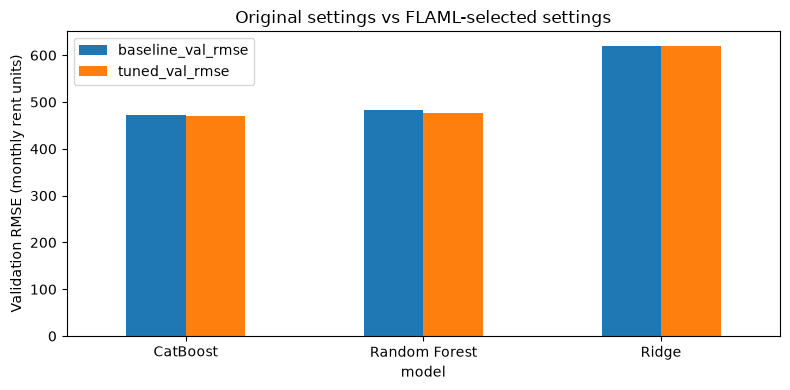

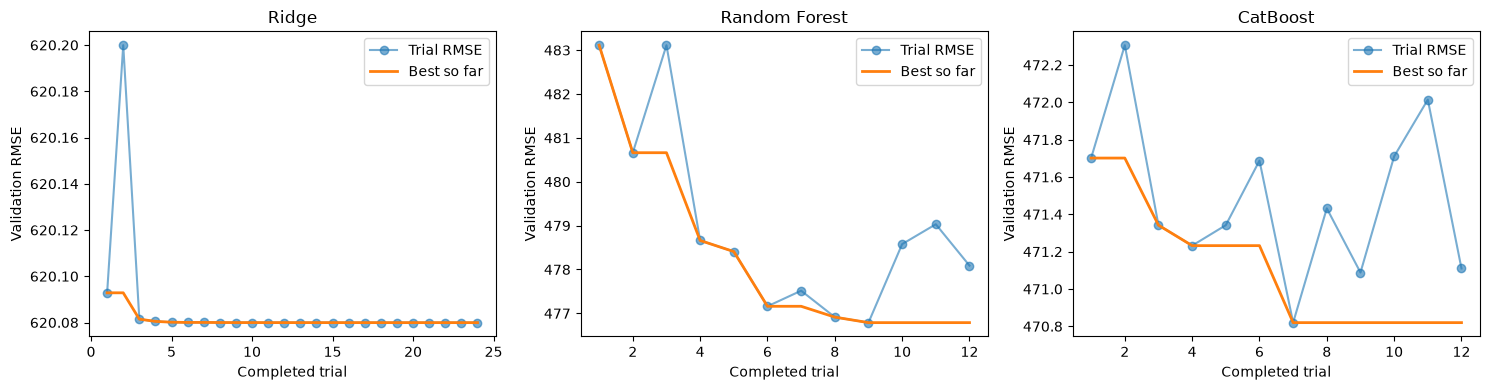

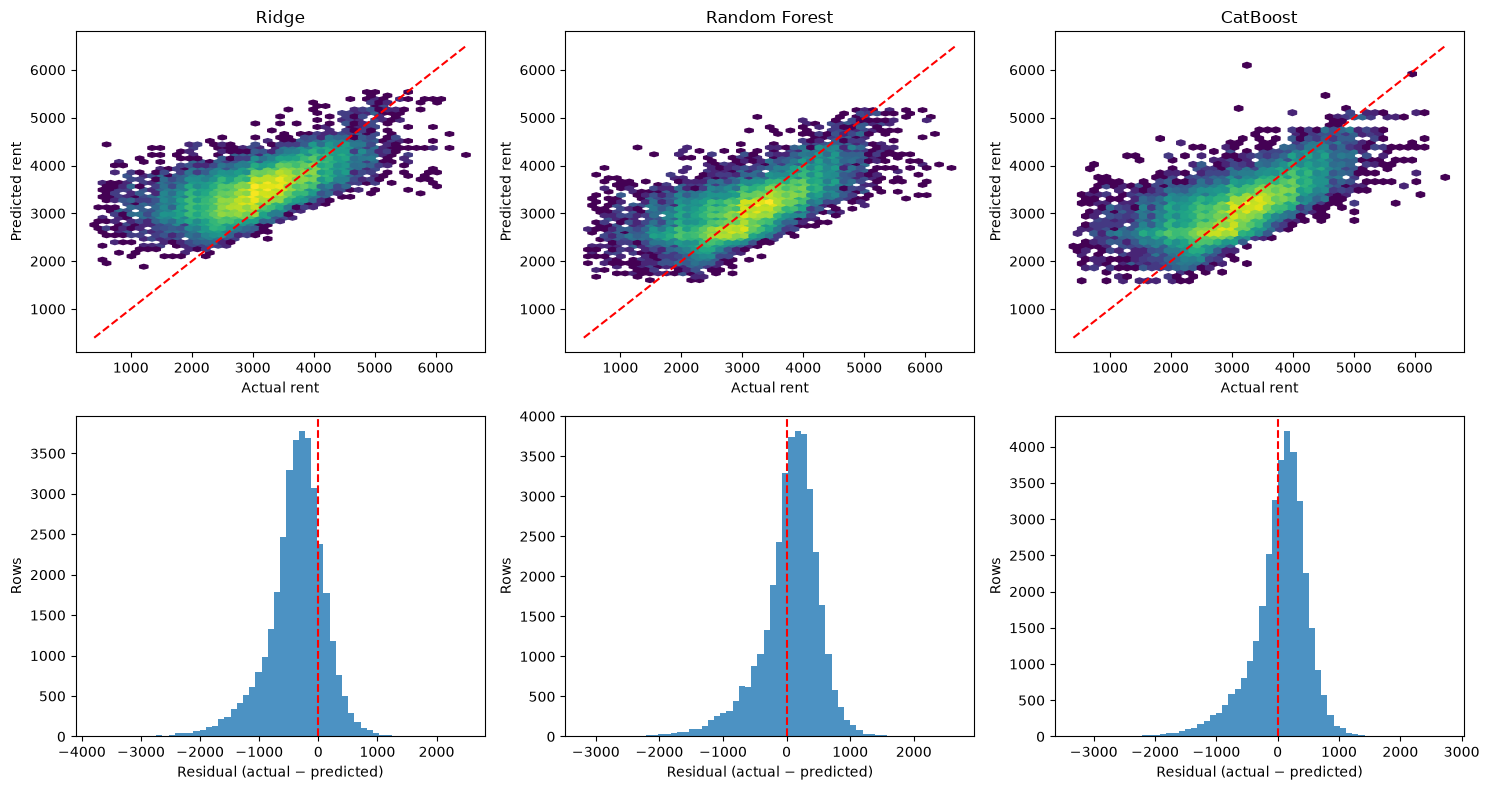

model,CatBoost,Random Forest,Ridge
month,,,
2024-04-01,506.28,513.98,561.62
2024-05-01,496.64,499.93,565.74
2024-06-01,503.25,505.60,585.91
2024-07-01,491.10,501.73,570.31
2024-08-01,460.97,466.05,574.82
2024-09-01,469.55,475.22,610.72
2024-10-01,435.80,445.87,582.83
2024-11-01,459.64,467.10,625.47
2024-12-01,442.37,447.90,642.14


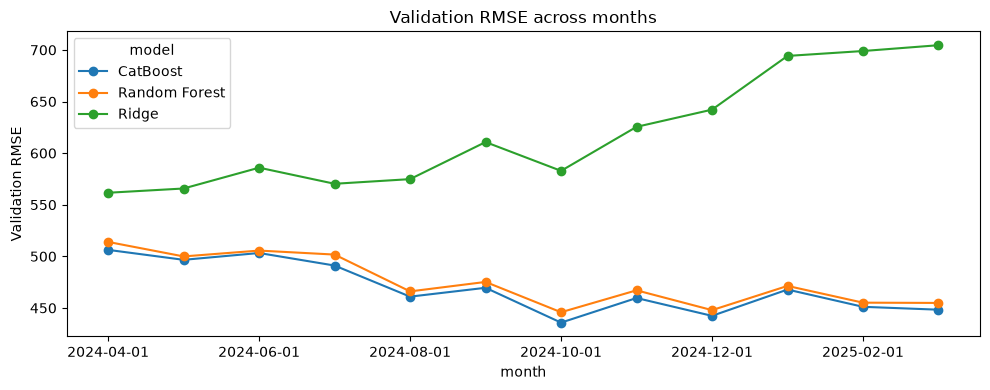

In [10]:
trials = pd.DataFrame(history)
comparison_rows = []
for name in SPACES:
    subset = trials[trials.model.eq(name)]
    baseline = subset.iloc[0]
    best = subset.loc[subset.val_rmse.idxmin()]
    comparison_rows.append({'model': name, 'completed_trials': len(subset),
        'baseline_val_rmse': baseline.val_rmse, 'tuned_val_rmse': best.val_rmse,
        'rmse_improvement_pct': 100*(baseline.val_rmse-best.val_rmse)/baseline.val_rmse,
        'tuned_val_mae': best.val_mae, 'tuned_val_r2': best.val_r2,
        'tuned_train_rmse': best.train_rmse, 'search_seconds': subset.trial_seconds.sum(),
        'best_trial': int(best.trial)})
comparison = pd.DataFrame(comparison_rows).sort_values('tuned_val_rmse')
display(comparison.round(4))
comparison.to_csv(OUT/'model_comparison.csv', index=False)
selected = {name: {**best_configs[name], **({'iterations': best_models[name].tree_count_} if name == 'CatBoost' else {})} for name in SPACES}
display(pd.DataFrame([{'model': name, 'searched_config': json.dumps(best_configs[name], default=lambda x: x.item()),
                       'refit_config': json.dumps(selected[name], default=lambda x: x.item())} for name in SPACES]))
(OUT/'best_parameters.json').write_text(json.dumps(selected, indent=2, default=lambda x: x.item()))
validation_predictions = pd.DataFrame({'source_row': validation_data.index, 'actual': y_val_raw.to_numpy(), **best_predictions})
validation_predictions.to_csv(OUT/'validation_predictions.csv', index=False)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(PLOTS/f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

comparison.set_index('model')[['baseline_val_rmse','tuned_val_rmse']].plot.bar(figsize=(8,4), rot=0)
plt.ylabel('Validation RMSE (monthly rent units)')
plt.title('Original settings vs FLAML-selected settings')
save_plot('baseline_vs_tuned')

fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, name in zip(axes, SPACES):
    h = trials[trials.model.eq(name)]
    ax.plot(h.trial, h.val_rmse, 'o-', alpha=.6, label='Trial RMSE')
    ax.plot(h.trial, h.val_rmse.cummin(), linewidth=2, label='Best so far')
    ax.set(title=name, xlabel='Completed trial', ylabel='Validation RMSE')
    ax.legend()
save_plot('search_progress')

fig, axes = plt.subplots(2,3,figsize=(15,8))
for j, name in enumerate(SPACES):
    pred = best_predictions[name]
    axes[0,j].hexbin(y_val_raw, pred, gridsize=45, mincnt=1, bins='log', cmap='viridis')
    limits = [min(y_val_raw.min(), pred.min()), max(y_val_raw.max(), pred.max())]
    axes[0,j].plot(limits, limits, 'r--')
    axes[0,j].set(title=name, xlabel='Actual rent', ylabel='Predicted rent')
    axes[1,j].hist(y_val_raw-pred, bins=60, alpha=.8)
    axes[1,j].axvline(0, color='red', linestyle='--')
    axes[1,j].set(xlabel='Residual (actual − predicted)', ylabel='Rows')
save_plot('validation_diagnostics')

monthly_rows = []
for month, group in validation_data.groupby('RENT_APPROVAL_DATE'):
    positions = validation_data.index.get_indexer(group.index)
    for name in SPACES:
        monthly_rows.append({'month': month, 'model': name, 'rows': len(group),
                            'rmse': root_mean_squared_error(group[TARGET], best_predictions[name][positions])})
monthly = pd.DataFrame(monthly_rows)
display(monthly.pivot(index='month', columns='model', values='rmse').round(2))
monthly.to_csv(OUT/'monthly_validation_rmse.csv', index=False)
monthly.pivot(index='month', columns='model', values='rmse').plot(figsize=(10,4), marker='o')
plt.ylabel('Validation RMSE'); plt.title('Validation RMSE across months')
save_plot('monthly_validation_rmse')

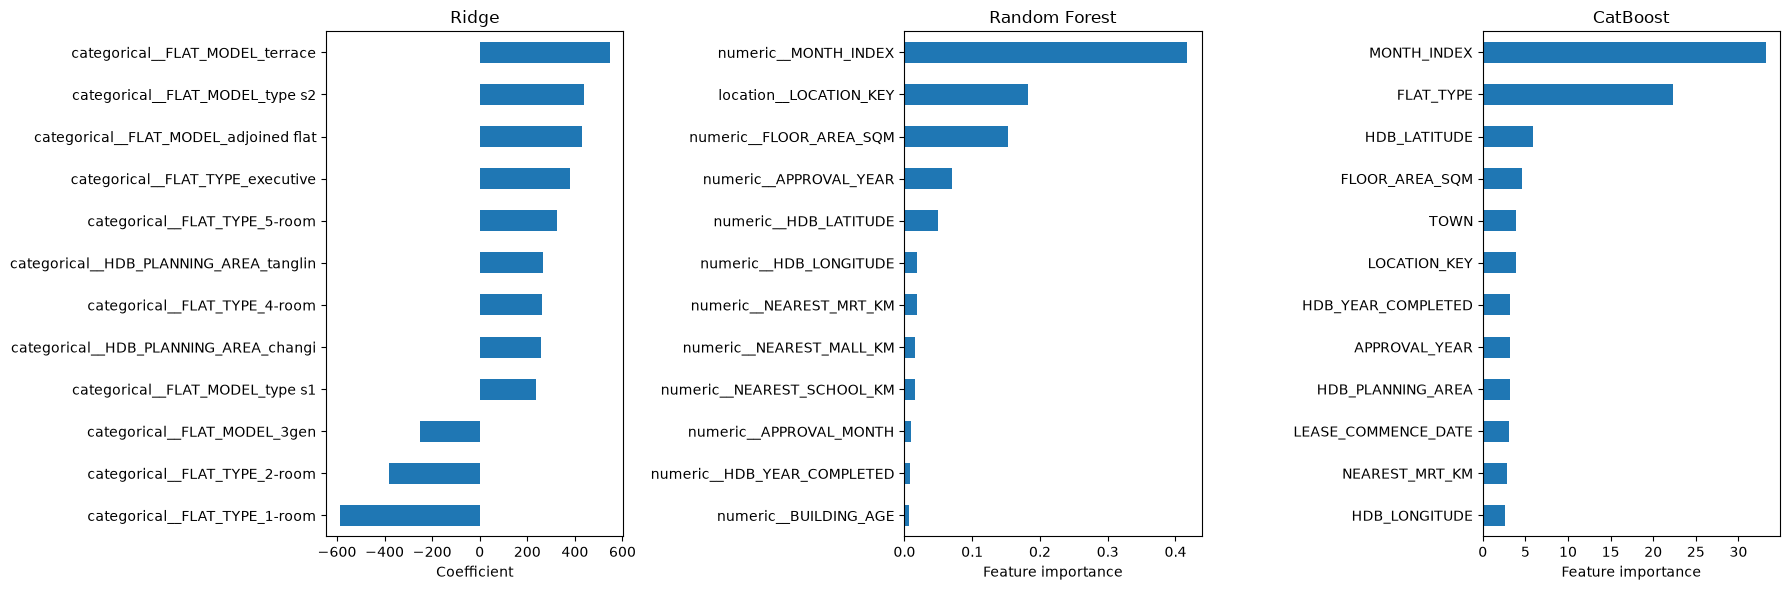

Importance scales differ across models; these are associations, not causal effects.


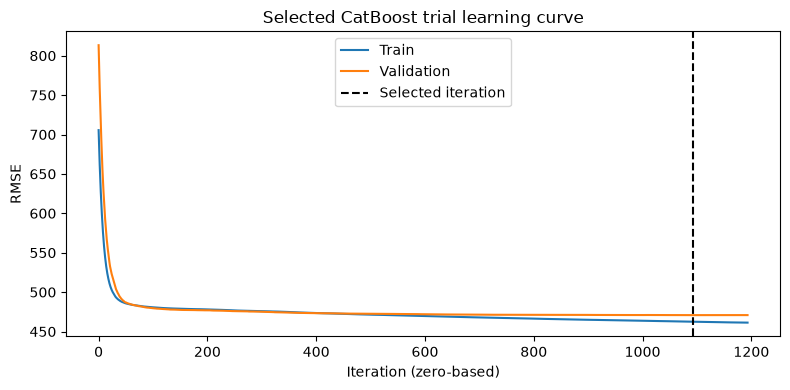

In [11]:
fig, axes = plt.subplots(1,3,figsize=(18,6))
importance_series = {
    'Ridge': pd.Series(best_models['Ridge'].coef_, index=ridge_preprocessor.get_feature_names_out()),
    'Random Forest': pd.Series(best_models['Random Forest'].feature_importances_, index=rf_feature_names),
    'CatBoost': pd.Series(best_models['CatBoost'].get_feature_importance(), index=CATBOOST_ALL_FEATURES),
}
for ax, (name, values) in zip(axes, importance_series.items()):
    values.to_csv(OUT/(name.lower().replace(' ', '_')+'_feature_effects.csv'), header=['value'])
    top = values.loc[values.abs().nlargest(12).index].sort_values()
    top.plot.barh(ax=ax)
    ax.set(title=name, xlabel='Coefficient' if name == 'Ridge' else 'Feature importance')
save_plot('feature_effects')
print('Importance scales differ across models; these are associations, not causal effects.')
curve = best_models['CatBoost'].get_evals_result()
plt.figure(figsize=(8,4))
plt.plot(curve['learn']['RMSE'], label='Train')
plt.plot(curve['validation']['RMSE'], label='Validation')
plt.axvline(best_models['CatBoost'].tree_count_-1, color='black', linestyle='--', label='Selected iteration')
plt.xlabel('Iteration (zero-based)'); plt.ylabel('RMSE'); plt.title('Selected CatBoost trial learning curve'); plt.legend()
save_plot('catboost_learning_curve')

## 5. Refit and test predictions
After completing model selection, fresh preprocessing and models are fitted on **all labeled rows**, matching the final-fit procedure in the main notebook. CatBoost uses the validation-selected number of trees without further early stopping. All 50,000 test rows remain in original order, with `Id = 0, …, n−1` and `Predicted`, matching the original submissions. Outputs go to a separate subdirectory to preserve existing predictions. No test metric is computed because labels are unavailable.

In [12]:
X_all, y_all = split_xy(train)
X_test_raw, _ = split_xy(test)
submission_summary = []
for name in SPACES:
    final_model = make_model(name, selected[name])
    if name == 'CatBoost':
        final_model.fit(make_catboost_features(train), y_all, cat_features=CATBOOST_CATEGORICAL, verbose=False)
        predictions = final_model.predict(make_catboost_features(test))
    else:
        preprocessor = clone(ridge_preprocessor if name == 'Ridge' else rf_preprocessor)
        X_full = preprocessor.fit_transform(X_all, y_all)
        X_test = preprocessor.transform(X_test_raw)
        final_model.fit(X_full, y_all)
        predictions = final_model.predict(X_test)
    assert len(predictions) == len(test) and np.isfinite(predictions).all()
    filename = name.lower().replace(' ', '_')+'_flaml_submission.csv'
    submission = pd.DataFrame({'Id': np.arange(len(test)), 'Predicted': predictions})
    submission.to_csv(PREDS/filename, index=False)
    submission_summary.append({'model': name, 'rows': len(submission), 'min': predictions.min(),
                               'mean': predictions.mean(), 'max': predictions.max(), 'file': filename})
    print(f'Saved {filename}: {len(submission):,} rows', flush=True)
display(pd.DataFrame(submission_summary))
pd.DataFrame(submission_summary).to_csv(OUT/'test_prediction_summary.csv', index=False)
best = comparison.iloc[0]
display(Markdown(f"**Best validation model: {best['model']}** — RMSE {best.tuned_val_rmse:,.2f}, "
                 f"MAE {best.tuned_val_mae:,.2f}, R² {best.tuned_val_r2:.4f}. "
                 f"Its RMSE improved {best.rmse_improvement_pct:.2f}% over its original settings. "
                 "These validation results were used for selection; test accuracy remains unknown."))

Saved ridge_flaml_submission.csv: 50,000 rows


/Users/apple/miniconda3/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/apple/miniconda3/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Saved random_forest_flaml_submission.csv: 50,000 rows


Saved catboost_flaml_submission.csv: 50,000 rows


,model,rows,min,mean,max,file
0,Ridge,50000,1892.598038,3630.361634,5754.332655,ridge_flaml_submission.csv
1,Random Forest,50000,1476.803720,3131.450318,5285.077558,random_forest_flaml_submission.csv
2,CatBoost,50000,1668.495030,3156.209384,5558.232977,catboost_flaml_submission.csv


**Best validation model: CatBoost** — RMSE 470.82, MAE 348.01, R² 0.4899. Its RMSE improved 0.19% over its original settings. These validation results were used for selection; test accuracy remains unknown.

## Interpretation and limits

CatBoost is best on the shared validation partition (RMSE **470.82**, MAE **348.01**, R² **0.4899**). Its improvement over the original settings is modest (**0.19%**). Random Forest improves by **1.31%**, from RMSE 483.11 to 476.79. Ridge barely changes (620.09 to 620.08); its selected alpha of 0.0001 is at the lower search boundary, so this search gives little evidence that stronger regularization helps.

The two tree models rank `MONTH_INDEX` highly, consistent with the importance of time in this chronological prediction task. Feature importance is not a causal explanation, and its scale is not comparable across model families. The validation diagnostics show a tendency to overpredict very low rents and underpredict very high rents.

These bounded searches do not establish globally optimal hyperparameters. Small score improvements have not been tested for statistical significance. Repeated use of this validation set for tuning and early stopping makes its score optimistic as an estimate of future performance. The test set remains unlabeled, so the saved submissions have no reported test accuracy.
